# 05b · Quick wins: error bars, object sizes, BM3D and low-light pipelines

**Kaggle · GPU T4 · Internet ON.** About 2–2.5 hours for the full run; run it as a commit (Save Version → Save & Run All).
Set `QUICK = True` first to check everything works on 40 images in about 10 minutes.

This notebook re-runs notebook 05's detection test on the **same 300 COCO images with the same seeds** (it checks that
clean mAP comes out at 0.387 again) and adds four things the report's limitations section asked for:

| # | Addition | Question it answers |
|---|---|---|
| 1 | **Bootstrap confidence intervals** | Which differences in the mAP table are real, and which are noise from using only 300 images? |
| 2 | **AP by object size** (small / medium / large) | Does damage hurt small objects most, and does restoration help them most? |
| 3 | **BM3D baseline** | Does DnCNN still win against the strongest classical denoiser, not just against NL-means? |
| 4 | **Low-light pipelines** (brighten and denoise, in both orders) | Was CLAHE bad because it brightens, or because it brightens *noise*? What happens if you denoise first? |

**Inputs** (Add Input): the same as notebook 05, plus BSD500 for the BM3D PSNR check.
- your committed **notebook 01** (for `degradations.py` and `best_classical.json`),
- the **dcnn-last** dataset (for `dncnn_last.pt`),
- **Berkeley Segmentation Dataset 500** (balraj98), optional: only used to compare BM3D's PSNR with the report's table.

**Outputs** (`/kaggle/working/outputs/05b`): `sweep.csv`, `per_image_ap.csv`, `bootstrap_runs.csv`,
`bootstrap_pairs.csv`, `ap_by_size.csv`, `bm3d_bsd_psnr.csv` and four figures.

In [1]:
!pip -q install ultralytics pycocotools bm3d

In [2]:
import os, json, random, sys, glob, time, io, contextlib
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from ultralytics import YOLO
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from skimage.metrics import peak_signal_noise_ratio as sk_psnr

def find_input(name):
    """Locate a file from an attached notebook output, wherever Kaggle mounted it."""
    hits = sorted(glob.glob(f"/kaggle/input/**/{name}", recursive=True))
    assert hits, f"{name} not found under /kaggle/input: add the notebook that produced it (Add Input -> Notebooks)"
    if len(hits) > 1:
        print(f"note: {len(hits)} copies of {name}, using {hits[0]}")
    return hits[0]

DEG_PY = find_input("degradations.py")                    # from notebook 01
sys.path.insert(0, os.path.dirname(DEG_PY))
from degradations import DEGRADATIONS, degrade
BEST = json.load(open(find_input("best_classical.json")))  # from notebook 01: tuned filter per (degradation, severity)
def resolve_checkpoint():
    """Find the DnCNN checkpoint. A .pt file is a zip archive, and Kaggle unzips zip files uploaded as a
    dataset, so an uploaded dncnn_last.pt can arrive as a folder holding data.pkl. Rebuild the file if so."""
    pts = sorted(glob.glob("/kaggle/input/**/*.pt", recursive=True) + glob.glob("/kaggle/input/**/*.pth", recursive=True))
    if pts:
        return pts[0]
    pkls = sorted(glob.glob("/kaggle/input/**/data.pkl", recursive=True))
    assert pkls, "no checkpoint under /kaggle/input: attach notebook 04 (Add Input -> Your Work -> Notebooks)"
    import zipfile
    root, out = os.path.dirname(pkls[0]), "/kaggle/working/dncnn_last.pt"
    with zipfile.ZipFile(out, "w", zipfile.ZIP_STORED) as z:      # torch expects uncompressed records under one folder
        for dirpath, _, files in os.walk(root):
            for f in sorted(files):
                full = os.path.join(dirpath, f)
                z.write(full, os.path.join("archive", os.path.relpath(full, root)))
    print(f"rebuilt {out} from the unpacked folder {root}")
    return out

CKPT_PATH = resolve_checkpoint()                           # from notebook 04

QUICK = False                       # True: 40 images, a few minutes, to check the pipeline
N_IMAGES = 300                      # the same 300-image subset as notebook 05 (QUICK uses its first 40)
SEED = 0
OUT_DIR = "/kaggle/working/outputs/05b" + ("_quick" if QUICK else ""); os.makedirs(OUT_DIR, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| degradations.py:", DEG_PY, "| checkpoint:", CKPT_PATH)
assert device == "cuda", "turn on Settings -> Accelerator -> GPU T4 (DnCNN on CPU would take hours)"

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
rebuilt /kaggle/working/dncnn_last.pt from the unpacked folder /kaggle/input/datasets/shourjabanerjee/dcnn-last/dncnn_last
device: cuda | degradations.py: /kaggle/input/datasets/shourjabanerjee/notebook01/degradations.py | checkpoint: /kaggle/working/dncnn_last.pt


## 1 · The same COCO subset as notebook 05

In [3]:
COCO_DIR = "/kaggle/working/coco"
os.makedirs(COCO_DIR, exist_ok=True)
# Check images and annotations separately: an interrupted run can leave one without the other
if len(glob.glob(f"{COCO_DIR}/val2017/*.jpg")) < 5000:
    !rm -rf {COCO_DIR}/val2017 {COCO_DIR}/val2017.zip
    !wget -q http://images.cocodataset.org/zips/val2017.zip -O {COCO_DIR}/val2017.zip
    !unzip -q -o {COCO_DIR}/val2017.zip -d {COCO_DIR} && rm {COCO_DIR}/val2017.zip
if not os.path.exists(f"{COCO_DIR}/annotations/instances_val2017.json"):
    !wget -q http://images.cocodataset.org/annotations/annotations_trainval2017.zip -O {COCO_DIR}/ann.zip
    !unzip -q -o {COCO_DIR}/ann.zip -d {COCO_DIR} && rm {COCO_DIR}/ann.zip
n_jpg = len(glob.glob(f"{COCO_DIR}/val2017/*.jpg"))
print(n_jpg, "COCO val2017 images on disk (want 5000)")
assert n_jpg == 5000, "COCO image download incomplete: is Settings -> Internet ON? Re-run this cell"
assert os.path.exists(f"{COCO_DIR}/annotations/instances_val2017.json"), "COCO annotations missing: is Settings -> Internet ON?"

with contextlib.redirect_stdout(io.StringIO()):
    coco_gt = COCO(f"{COCO_DIR}/annotations/instances_val2017.json")
img_ids = sorted(i for i in coco_gt.getImgIds() if len(coco_gt.getAnnIds(imgIds=i, iscrowd=False)) > 0)
random.Random(SEED).shuffle(img_ids)
img_ids = sorted(img_ids[:N_IMAGES])          # identical to notebook 05
if QUICK:
    img_ids = img_ids[:40]
json.dump(img_ids, open(f"{OUT_DIR}/subset_ids.json", "w"))   # freeze the subset: report it
n_objects = sum(len(coco_gt.getAnnIds(imgIds=i, iscrowd=False)) for i in img_ids)
print(f"{len(img_ids)} images, {n_objects} annotated objects")
if not QUICK:
    assert n_objects == 2035, "not the same subset as notebook 05 (2,035 objects): check SEED and N_IMAGES"

5000 COCO val2017 images on disk (want 5000)
300 images, 2035 annotated objects


## 2 · Detector and scoring

As in notebook 05, but `coco_map` now also returns AP for **small** (area < 32² px), **medium** and **large**
(> 96² px) objects, which COCOeval computes anyway (`stats[3:6]`).

In [4]:
detector = YOLO("yolov8n.pt")

# YOLO predicts class indices 0-79; COCO category ids run 1-90 with gaps (e.g. no id 12).
# YOLO's classes are COCO's 80 categories in increasing id order, so index i -> the i-th smallest id.
cat_ids = sorted(coco_gt.getCatIds())
assert len(cat_ids) == 80
coco_names = [coco_gt.loadCats(c)[0]["name"] for c in cat_ids]
mismatch = [(i, detector.names[i], coco_names[i]) for i in range(80) if detector.names[i] != coco_names[i]]
print("YOLO index -> COCO id, first five:", [(i, detector.names[i], cat_ids[i]) for i in range(5)])
print("name mismatches:", mismatch if mismatch else "none (the mapping lines up)")

def to_uint8_bgr(img):
    return (np.clip(img, 0, 1) * 255).round().astype(np.uint8)[:, :, ::-1]   # YOLO reads numpy arrays as BGR

def detect(img_rgb_float, image_id):
    """One float RGB image -> list of COCO result dicts {image_id, category_id, bbox [x, y, w, h], score}.
    conf=0.001 keeps low-confidence boxes: mAP integrates over the whole precision-recall curve, so a
    detector evaluated at a high threshold would be scored on a truncated curve."""
    r = detector.predict(np.ascontiguousarray(to_uint8_bgr(img_rgb_float)), conf=0.001, iou=0.7, max_det=300,
                         verbose=False, device=device)[0]
    xyxy = r.boxes.xyxy.cpu().numpy(); conf = r.boxes.conf.cpu().numpy(); cls = r.boxes.cls.cpu().numpy().astype(int)
    return [{"image_id": int(image_id), "category_id": int(cat_ids[c]),
             "bbox": [float(x1), float(y1), float(x2 - x1), float(y2 - y1)], "score": float(s)}
            for (x1, y1, x2, y2), s, c in zip(xyxy, conf, cls)]

def coco_eval(results, ids, quiet=True):
    """COCOeval stats on exactly these image ids: [AP, AP50, AP75, AP_small, AP_medium, AP_large, ...] (12 numbers)."""
    if not results:
        return np.zeros(12)
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        dt = coco_gt.loadRes(results)
        E = COCOeval(coco_gt, dt, "bbox"); E.params.imgIds = list(ids)
        E.evaluate(); E.accumulate(); E.summarize()
    if not quiet:
        print(buf.getvalue())
    return np.array(E.stats, dtype=float)

def coco_map(results, ids, quiet=True):
    """(mAP@[.5:.95], mAP@.5), as in notebook 05."""
    s = coco_eval(results, ids, quiet)
    return float(s[0]), float(s[1])

def per_image_ap(results, ids):
    """AP@[.5:.95] for each image separately (for the failure gallery in notebook 06)."""
    by_img = {}
    for r in results:
        by_img.setdefault(r["image_id"], []).append(r)
    out = {}
    for iid in ids:
        out[iid] = coco_map(by_img.get(iid, []), [iid])[0] if by_img.get(iid) else 0.0
    return out

YOLO index -> COCO id, first five: [(0, 'person', 1), (1, 'bicycle', 2), (2, 'car', 3), (3, 'motorcycle', 4), (4, 'airplane', 5)]
name mismatches: none (the mapping lines up)


## 3 · Clean baseline (reproducibility check)

Notebook 05 measured clean mAP = 0.387 on these 300 images. Getting the same number again shows that the subset,
the detector and the scoring are unchanged, so the new results can sit in the same table as the old ones.

In [5]:
def load_coco_rgb(image_id):
    info = coco_gt.loadImgs(image_id)[0]
    return cv2.imread(f"{COCO_DIR}/val2017/{info['file_name']}", cv2.IMREAD_COLOR)[:, :, ::-1].astype(np.float32) / 255.0

t0 = time.time()
clean_imgs = {iid: load_coco_rgb(iid) for iid in img_ids}
clean_results = []
for iid in img_ids:
    clean_results += detect(clean_imgs[iid], iid)
clean_stats = coco_eval(clean_results, img_ids, quiet=False)
clean_map = float(clean_stats[0])
print(f"clean mAP@[.5:.95] = {clean_map:.3f}  (notebook 05: 0.387)   small / medium / large AP = "
      f"{clean_stats[3]:.3f} / {clean_stats[4]:.3f} / {clean_stats[5]:.3f}   ({time.time() - t0:.0f} s)")
assert clean_map > 0.2, "clean mAP is far too low: something is wrong before any degradation is applied"
if not QUICK:
    assert abs(clean_map - 0.387) < 0.003, "clean mAP differs from notebook 05: not the same setup"

# How many objects of each size the subset has (COCO's thresholds are on segmentation area)
areas = [a["area"] for a in coco_gt.loadAnns(coco_gt.getAnnIds(imgIds=img_ids, iscrowd=False))]
size_counts = {"small": sum(a < 32**2 for a in areas), "medium": sum(32**2 <= a < 96**2 for a in areas),
               "large": sum(a >= 96**2 for a in areas)}
print("objects by size:", size_counts)

Loading and preparing results...
DONE (t=0.05s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=3.04s).
Accumulating evaluation results...
DONE (t=0.91s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.387
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.541
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.421
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.197
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.475
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.554
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.322
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.520
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.566
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=10

## 4 · Restorers: notebook 05's, plus BM3D and the low-light pipelines

**BM3D** (Dabov et al., 2007) groups similar patches into 3-D stacks and shrinks them together in a transform
domain. It is the classic state of the art among non-learned denoisers and the main baseline in the DnCNN paper.
Like the tuned classical filters, it is given the **true σ** (an oracle advantage).

**Low-light pipelines.** Section 12 of the report argued that CLAHE hurts detection because it amplifies the
noise along with the brightness, while DnCNN helps because it removes the noise but leaves the darkness. If that is
right, then *denoise first, brighten second* should beat both. We test five combinations:

| Name | Steps |
|---|---|
| `gamma` | brighten only, with an automatic gamma curve that lifts mean brightness to 0.45 |
| `gamma>dncnn` | brighten, then denoise (the brightened noise is larger, but still Gaussian-like) |
| `dncnn>gamma` | denoise, then brighten |
| `dncnn>clahe_L` | denoise, then CLAHE on L |
| `clahe_L>dncnn` | CLAHE on L, then denoise |

The gamma curve is **blind**: it looks only at the image's own brightness, not at the true ℓ.

In [6]:
# --- DnCNN, exactly as defined in notebook 04 (the checkpoint only stores weights) ---------------
class DnCNN(nn.Module):
    def __init__(self, channels=3, depth=17, features=64):
        super().__init__()
        layers = [nn.Conv2d(channels, features, kernel_size=3, padding=1), nn.ReLU(inplace=True)]
        for _ in range(depth - 2):
            layers += [nn.Conv2d(features, features, kernel_size=3, padding=1, bias=False),
                       nn.BatchNorm2d(features), nn.ReLU(inplace=True)]
        layers += [nn.Conv2d(features, channels, kernel_size=3, padding=1)]
        self.body = nn.Sequential(*layers)
    def forward(self, y):
        return self.body(y)

ck = torch.load(CKPT_PATH, map_location=device, weights_only=False)
dncnn = DnCNN(ck["cfg"]["channels"], ck["cfg"]["depth"], ck["cfg"]["features"]).to(device)
dncnn.load_state_dict(ck["model"]); dncnn.eval()
print(f"DnCNN loaded: trained {ck['epoch'] + 1} epochs, final train loss {ck['history'][-1]:.5f}")

@torch.no_grad()
def dncnn_restore(img):
    """Full float32: under fp16 autocast some activations overflow to NaN on out-of-distribution inputs (JPEG)."""
    y = torch.from_numpy(np.ascontiguousarray(img.transpose(2, 0, 1))).unsqueeze(0).to(device)
    out = (y - dncnn(y)).clamp(0, 1)[0].permute(1, 2, 0).cpu().numpy().astype(np.float32)
    assert np.isfinite(out).all(), "DnCNN produced NaN/inf"
    return out

# --- Classical filters, exactly as in notebook 01 ------------------------------------------------
def to_u8(img):  return (np.clip(img, 0, 1) * 255).round().astype(np.uint8)
def from_u8(u8): return u8.astype(np.float32) / 255.0
def f_median(img, k=3):     return from_u8(cv2.medianBlur(to_u8(img), k))
def f_gaussian(img, sigma=1.0):
    return np.clip(cv2.GaussianBlur(img.astype(np.float32), (0, 0), sigmaX=sigma, borderType=cv2.BORDER_REFLECT), 0, 1)
def f_bilateral(img, d=7, sigma_color=0.1, sigma_space=5):
    return np.clip(cv2.bilateralFilter(img.astype(np.float32), d, sigma_color, sigma_space), 0, 1)
def f_nlmeans(img, h=10):   return from_u8(cv2.fastNlMeansDenoisingColored(to_u8(img), None, h, h, 7, 21))
FILTERS = {"median": f_median, "gaussian": f_gaussian, "bilateral": f_bilateral, "nlmeans": f_nlmeans}

def classical_restore(img, name, severity):
    """The filter + parameters notebook 01 tuned for exactly this (degradation, severity)."""
    entry = BEST[name][str(severity)]
    if entry["filter"] == "none":
        return img
    return FILTERS[entry["filter"]](img, **entry["params"])

def clahe_L(img, clip=2.0, tiles=8):
    """Notebook 01, Experiment 3: CLAHE on Lab's L channel only (brightness without colour shift)."""
    lab = cv2.cvtColor(to_u8(img), cv2.COLOR_RGB2Lab)
    lab[..., 0] = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tiles, tiles)).apply(lab[..., 0])
    return from_u8(cv2.cvtColor(lab, cv2.COLOR_Lab2RGB))

# Conditions use notebook 01's severities, so every one has a tuned classical entry
CONDITIONS = {
    "gaussian":  [15, 25, 35, 50],
    "jpeg":      [70, 50, 30, 10],
    "low_light": [0.4, 0.6, 0.8, 0.9],
}
for name, levels in CONDITIONS.items():
    for s in levels:
        assert str(s) in BEST[name] and s in DEGRADATIONS[name][1], (name, s)

# --- BM3D: the strongest classical denoiser, given the true sigma like the tuned filters -------------
try:
    import bm3d
    HAVE_BM3D = True
except Exception as e:                       # never let a failed install stop the rest of the run
    HAVE_BM3D = False
    print("BM3D unavailable, its parts will be skipped:", repr(e))

def bm3d_restore(img, sigma):
    return np.clip(bm3d.bm3d_rgb(img.astype(np.float64), sigma / 255.0), 0, 1).astype(np.float32)

def _bm3d_job(args):
    img, sigma = args
    return bm3d_restore(img, sigma)

def bm3d_many(imgs, sigma):
    """BM3D is CPU-only and slow (seconds per image), so spread it over all CPU cores."""
    from multiprocessing import get_context
    with get_context("fork").Pool(os.cpu_count()) as pool:
        return pool.map(_bm3d_job, [(im, sigma) for im in imgs], chunksize=2)

# --- Blind brightening ------------------------------------------------------------------------------
def auto_gamma(img, target=0.45):
    """Raise every channel to the power g chosen so that mean luma becomes `target`. Blind: uses only the image."""
    luma = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
    m = float(np.clip(luma.mean(), 1e-3, 0.999))
    g = np.log(target) / np.log(m)
    return np.clip(img, 0, 1) ** g

def chain(*steps):
    """Compose restorers left to right: chain(a, b)(img) = b(a(img))."""
    def run(img, name, s):
        for step in steps:
            img = np.clip(step(img, name, s), 0, 1).astype(np.float32)
        return img
    return run

RESTORERS = {
    "none":      lambda img, name, s: img,
    "classical": classical_restore,
    "dncnn":     lambda img, name, s: dncnn_restore(img),
    "clahe_L":   lambda img, name, s: clahe_L(img),
    "gamma":     lambda img, name, s: auto_gamma(img),
}
RESTORERS["gamma>dncnn"]   = chain(RESTORERS["gamma"], RESTORERS["dncnn"])
RESTORERS["dncnn>gamma"]   = chain(RESTORERS["dncnn"], RESTORERS["gamma"])
RESTORERS["dncnn>clahe_L"] = chain(RESTORERS["dncnn"], RESTORERS["clahe_L"])
RESTORERS["clahe_L>dncnn"] = chain(RESTORERS["clahe_L"], RESTORERS["dncnn"])
BM3D_SIGMAS = [15, 25, 35, 50]   # about 10 min per sigma on Kaggle's 4 CPU cores; trim this list to save time
APPLIES = {"gaussian": ["none", "classical", "dncnn"] + (["bm3d"] if HAVE_BM3D else []),
           "jpeg": ["none", "classical", "dncnn"],
           "low_light": ["none", "classical", "dncnn", "clahe_L",
                         "gamma", "gamma>dncnn", "dncnn>gamma", "dncnn>clahe_L", "clahe_L>dncnn"]}
print("classical filter chosen per condition:",
      {f"{n} {s}": BEST[n][str(s)]["filter"] for n, lv in CONDITIONS.items() for s in lv})

DnCNN loaded: trained 50 epochs, final train loss 0.00104
classical filter chosen per condition: {'gaussian 15': 'bilateral', 'gaussian 25': 'bilateral', 'gaussian 35': 'bilateral', 'gaussian 50': 'gaussian', 'jpeg 70': 'bilateral', 'jpeg 50': 'bilateral', 'jpeg 30': 'bilateral', 'jpeg 10': 'bilateral', 'low_light 0.4': 'gaussian', 'low_light 0.6': 'gaussian', 'low_light 0.8': 'gaussian', 'low_light 0.9': 'gaussian'}


In [7]:
# Sanity checks before the long run
rng = np.random.default_rng(1)
yy, xx = np.mgrid[0:96, 0:96] / 96.0
toy = np.stack([0.2 + 0.6 * xx, 0.5 + 0.3 * np.sin(6 * yy), 0.3 + 0.4 * (xx > 0.5)], -1).astype(np.float32)
toy_noisy = np.clip(toy + rng.normal(0, 25 / 255, toy.shape), 0, 1).astype(np.float32)
psnr = lambda a, b: sk_psnr(a, b, data_range=1.0)
if HAVE_BM3D:
    t0 = time.time(); den = bm3d_restore(toy_noisy, 25); dt = time.time() - t0
    print(f"BM3D on a 96x96 toy image: {psnr(toy, toy_noisy):.2f} -> {psnr(toy, den):.2f} dB in {dt:.1f} s")
    assert psnr(toy, den) > psnr(toy, toy_noisy) + 4, "BM3D is not denoising: check the bm3d package version"
dark = (0.05 * toy).astype(np.float32)
lit = auto_gamma(dark)
print(f"auto_gamma: mean {dark.mean():.3f} -> {lit.mean():.3f} (target luma 0.45)")
assert 0.35 < lit.mean() < 0.55 and np.isfinite(lit).all()
order = chain(lambda im, n, s: im + 0.1, lambda im, n, s: im * 2)(np.zeros((2, 2, 3), np.float32), None, None)
assert np.allclose(order, 0.2), "chain() must apply steps left to right"
print("restorer checks passed")

BM3D on a 96x96 toy image: 20.27 -> 37.31 dB in 3.1 s
auto_gamma: mean 0.025 -> 0.443 (target luma 0.45)
restorer checks passed


## 5 · BM3D on BSD500: is it really stronger than our classical filters?

Before using BM3D for detection, check its PSNR on the **same 96 BSD500 test images and the same noise** as the
report's section 10 table. Expected order: tuned classical < BM3D < DnCNN.

In [8]:
REPORT = {15: dict(noisy=24.82, classical=30.90, dncnn=33.76),
          25: dict(noisy=20.53, classical=27.56, dncnn=31.05),
          50: dict(noisy=15.00, classical=23.20, dncnn=27.69)}

val_dirs = [d for d in sorted(glob.glob("/kaggle/input/**/images/val", recursive=True)) if glob.glob(f"{d}/*.jpg")]
if not HAVE_BM3D:
    print("skipped: BM3D unavailable")
elif not val_dirs:
    print("skipped: BSD500 not attached (Add Input -> Datasets -> 'berkeley segmentation dataset 500', balraj98)")
else:
    paths = sorted(glob.glob(f"{val_dirs[0]}/*.jpg"))
    bsd_test = [cv2.imread(p)[:, :, ::-1].astype(np.float32) / 255.0 for p in paths][4:]   # the same 96 test images
    if QUICK:
        bsd_test = bsd_test[:8]
    assert QUICK or len(bsd_test) == 96

    def noisy_like_nb01(clean, i, sigma):
        """Same noise as notebooks 01 and 04 for test image i."""
        levels = DEGRADATIONS["gaussian"][1]
        rng = np.random.default_rng([SEED, i, list(DEGRADATIONS).index("gaussian"), levels.index(sigma)])
        return np.clip(clean + rng.normal(0, sigma / 255, clean.shape), 0, 1).astype(np.float32)

    bsd_rows = []
    for sigma in [15, 25, 50]:
        t0 = time.time()
        noisy = [noisy_like_nb01(c, i, sigma) for i, c in enumerate(bsd_test)]
        den = bm3d_many(noisy, sigma)
        p_noisy = np.mean([psnr(c, n) for c, n in zip(bsd_test, noisy)])
        p_bm3d = [psnr(c, d) for c, d in zip(bsd_test, den)]
        bsd_rows.append(dict(sigma=sigma, noisy=p_noisy, bm3d=float(np.mean(p_bm3d)), **{f"report_{k}": v for k, v in REPORT[sigma].items()}))
        print(f"sigma {sigma}: noisy {p_noisy:.2f} (report {REPORT[sigma]['noisy']:.2f}) | classical {REPORT[sigma]['classical']:.2f} | "
              f"BM3D {np.mean(p_bm3d):.2f} | DnCNN {REPORT[sigma]['dncnn']:.2f} dB   ({time.time() - t0:.0f} s)")
        if not QUICK:
            assert abs(p_noisy - REPORT[sigma]["noisy"]) < 0.02, "noise differs from notebooks 01/04"
    pd.DataFrame(bsd_rows).round(2).to_csv(f"{OUT_DIR}/bm3d_bsd_psnr.csv", index=False)

sigma 15: noisy 24.82 (report 24.82) | classical 30.90 | BM3D 33.20 | DnCNN 33.76 dB   (1215 s)
sigma 25: noisy 20.53 (report 20.53) | classical 27.56 | BM3D 30.18 | DnCNN 31.05 dB   (1137 s)
sigma 50: noisy 15.00 (report 15.00) | classical 23.20 | BM3D 25.92 | DnCNN 27.69 dB   (1330 s)


## 6 · The sweep

Notebook 05's conditions and restorers, plus BM3D on Gaussian noise and the five low-light pipelines. Per-image
AP is now saved for **every** run (the bootstrap needs it), and each run records AP by object size.
Results are cached after every run, so if the session drops, re-running this cell continues where it stopped.

In [9]:
CSV = f"{OUT_DIR}/sweep.csv"
PI_CSV = f"{OUT_DIR}/per_image_ap.csv"
rows = pd.read_csv(CSV).to_dict("records") if os.path.exists(CSV) else []
per_image_rows = pd.read_csv(PI_CSV).to_dict("records") if os.path.exists(PI_CSV) else []
done = {(r["degradation"], r["severity"], r["restorer"]) for r in rows}

def record(name, s, rname, outs, t0):
    results, psnrs = [], []
    for iid, out in zip(img_ids, outs):
        psnrs.append(sk_psnr(clean_imgs[iid], out, data_range=1.0))
        results += detect(out, iid)
    st = coco_eval(results, img_ids)
    for (iid, ap), p in zip(per_image_ap(results, img_ids).items(), psnrs):
        per_image_rows.append(dict(degradation=name, severity=s, restorer=rname, image_id=iid, ap=ap, psnr=p))
    pd.DataFrame(per_image_rows).to_csv(PI_CSV, index=False)      # per-image first: a run counts as done only once both exist
    rows.append(dict(degradation=name, severity=s, restorer=rname, map=st[0], map50=st[1],
                     ap_small=st[3], ap_medium=st[4], ap_large=st[5], psnr=float(np.mean(psnrs))))
    pd.DataFrame(rows).to_csv(CSV, index=False)
    print(f"{name:9s} {s!s:>4} {rname:14s} mAP {st[0]:.3f}  S/M/L {st[3]:.3f}/{st[4]:.3f}/{st[5]:.3f}  "
          f"PSNR {rows[-1]['psnr']:5.2f}  ({time.time() - t0:.0f} s)")

if ("clean", 0, "none") not in done:
    record("clean", 0, "none", [clean_imgs[iid] for iid in img_ids], time.time())

t_start = time.time()
for name, levels in CONDITIONS.items():
    for s in levels:
        todo = [r for r in APPLIES[name] if (name, s, r) not in done and not (r == "bm3d" and s not in BM3D_SIGMAS)]
        if not todo:
            continue
        sev_idx = DEGRADATIONS[name][1].index(s)
        degraded = [degrade(clean_imgs[iid], name, s, np.random.default_rng([SEED, k, list(DEGRADATIONS).index(name), sev_idx]))
                    for k, iid in enumerate(img_ids)]     # identical to notebook 05: k is the position in the full subset
        for rname in todo:
            t0 = time.time()
            if rname == "bm3d":
                outs = bm3d_many(degraded, s)
            else:
                outs = [np.clip(RESTORERS[rname](img, name, s), 0, 1).astype(np.float32) for img in degraded]
            record(name, s, rname, outs, t0)
print(f"sweep done in {(time.time() - t_start) / 60:.1f} min")

df = pd.read_csv(CSV)
pi = pd.read_csv(PI_CSV)
old = {("gaussian", 25, "dncnn"): 0.354, ("jpeg", 10, "classical"): 0.231, ("low_light", 0.8, "clahe_L"): 0.095}
for (n, s, r), v in old.items():
    got = df[(df.degradation == n) & (df.severity == s) & (df.restorer == r)]["map"]
    if len(got) and not QUICK:
        print(f"check against notebook 05: {n} {s} {r}: {got.iloc[0]:.3f} (was {v:.3f})")
        assert abs(got.iloc[0] - v) < 0.003, "results differ from notebook 05"

/usr/local/lib/python3.13/dist-packages/skimage/metrics/simple_metrics.py:168: RuntimeWarning: divide by zero encountered in scalar divide
  return 10 * np.log10((data_range**2) / err)


clean        0 none           mAP 0.387  S/M/L 0.197/0.475/0.554  PSNR   inf  (19 s)
gaussian    15 none           mAP 0.319  S/M/L 0.176/0.392/0.465  PSNR 24.94  (20 s)
gaussian    15 classical      mAP 0.359  S/M/L 0.203/0.426/0.535  PSNR 30.96  (27 s)
gaussian    15 dncnn          mAP 0.375  S/M/L 0.199/0.442/0.553  PSNR 32.91  (42 s)
gaussian    15 bm3d           mAP 0.371  S/M/L 0.195/0.443/0.548  PSNR 32.85  (6425 s)
gaussian    25 none           mAP 0.241  S/M/L 0.113/0.324/0.362  PSNR 20.70  (19 s)
gaussian    25 classical      mAP 0.305  S/M/L 0.161/0.365/0.488  PSNR 27.57  (26 s)
gaussian    25 dncnn          mAP 0.354  S/M/L 0.186/0.422/0.542  PSNR 30.73  (42 s)
gaussian    25 bm3d           mAP 0.343  S/M/L 0.185/0.420/0.521  PSNR 29.98  (6201 s)
gaussian    35 none           mAP 0.181  S/M/L 0.100/0.243/0.250  PSNR 17.97  (17 s)
gaussian    35 classical      mAP 0.264  S/M/L 0.140/0.330/0.401  PSNR 25.73  (24 s)
gaussian    35 dncnn          mAP 0.326  S/M/L 0.168/0.388/0.

## 7 · Win 1: how sure are we? Bootstrap confidence intervals

The mAP table comes from one set of 300 images. A different 300 would give slightly different numbers. The
**bootstrap** estimates how much: draw 300 images *with replacement* from our 300, recompute the score, repeat
2,000 times, and take the middle 95% of the results as the confidence interval.

COCO mAP pools detections across images, so it cannot be cheaply recomputed on a resample. We therefore bootstrap the
**image-averaged AP** (the mean of each image's own AP), which ranks the runs almost exactly like mAP (the
correlation is printed below). For comparisons the bootstrap is **paired**: both restorers are evaluated on the same
resampled images, which removes the image-to-image variation they share. A difference is called **clear** when its 95%
interval excludes zero.

In [10]:
B = 2000
boot_rng = np.random.default_rng(12345)
n_img = len(img_ids)
IDX = boot_rng.integers(0, n_img, size=(B, n_img))         # the same resamples for every run, so pairs line up

def ap_vector(name, s, r):
    sub = pi[(pi.degradation == name) & (pi.severity == s) & (pi.restorer == r)].set_index("image_id").loc[img_ids]
    return sub["ap"].to_numpy()

runs = df[["degradation", "severity", "restorer", "map"]].copy()
lo, hi, mean_ap = [], [], []
for r in runs.itertuples():
    v = ap_vector(r.degradation, r.severity, r.restorer)
    bs = v[IDX].mean(axis=1)
    mean_ap.append(v.mean()); lo.append(np.percentile(bs, 2.5)); hi.append(np.percentile(bs, 97.5))
runs["img_avg_ap"], runs["ci_low"], runs["ci_high"] = mean_ap, lo, hi
runs.round(4).to_csv(f"{OUT_DIR}/bootstrap_runs.csv", index=False)
from scipy.stats import spearmanr
print(f"image-averaged AP vs COCO mAP across {len(runs)} runs: Spearman {spearmanr(runs.img_avg_ap, runs['map']).correlation:.3f}")

def compare(name, s, a, b):
    """Paired bootstrap of (a - b) in image-averaged AP."""
    d = ap_vector(name, s, a) - ap_vector(name, s, b)
    bs = d[IDX].mean(axis=1)
    lo_, hi_ = np.percentile(bs, [2.5, 97.5])
    return dict(degradation=name, severity=s, a=a, b=b, diff=d.mean(), ci_low=lo_, ci_high=hi_,
                p_a_better=float((bs > 0).mean()), clear=bool(lo_ > 0 or hi_ < 0))

pairs = []
for name, levels in CONDITIONS.items():
    for s in levels:
        present = set(df[(df.degradation == name) & (df.severity == s)].restorer)
        rs = [r for r in APPLIES[name] if r in present]
        for i, a in enumerate(rs):
            for b in rs[i + 1:]:
                pairs.append(compare(name, s, a, b))
pairs = pd.DataFrame(pairs)
pairs.round(4).to_csv(f"{OUT_DIR}/bootstrap_pairs.csv", index=False)

KEY = [("gaussian", s, "dncnn", "classical") for s in CONDITIONS["gaussian"]] + \
      [("gaussian", s, "classical", "none") for s in CONDITIONS["gaussian"]] + \
      [("jpeg", s, "classical", "none") for s in CONDITIONS["jpeg"]] + \
      [("jpeg", s, "dncnn", "none") for s in CONDITIONS["jpeg"]] + \
      [("low_light", s, "dncnn", "none") for s in CONDITIONS["low_light"]] + \
      [("low_light", s, "clahe_L", "none") for s in CONDITIONS["low_light"]]
def lookup(n, s, a, b):
    m = pairs[(pairs.degradation == n) & (pairs.severity == s) & (((pairs.a == a) & (pairs.b == b)) | ((pairs.a == b) & (pairs.b == a)))]
    if not len(m):
        return None
    row = m.iloc[0].to_dict()
    if row["a"] != a:            # flip so the difference reads a - b
        row.update(a=a, b=b, diff=-row["diff"], ci_low=-row["ci_high"], ci_high=-row["ci_low"], p_a_better=1 - row["p_a_better"])
    return row
key = pd.DataFrame([x for x in (lookup(*k) for k in KEY) if x])
print("\nKey comparisons (difference in image-averaged AP, 95% CI; 'clear' = the interval excludes 0):")
print(key[["degradation", "severity", "a", "b", "diff", "ci_low", "ci_high", "clear"]].round(3).to_string(index=False))

image-averaged AP vs COCO mAP across 65 runs: Spearman 0.997

Key comparisons (difference in image-averaged AP, 95% CI; 'clear' = the interval excludes 0):
degradation  severity         a         b   diff  ci_low  ci_high  clear
   gaussian      15.0     dncnn classical  0.010  -0.002    0.024  False
   gaussian      25.0     dncnn classical  0.029   0.011    0.046   True
   gaussian      35.0     dncnn classical  0.057   0.036    0.078   True
   gaussian      50.0     dncnn classical  0.146   0.124    0.168   True
   gaussian      15.0 classical      none  0.030   0.015    0.045   True
   gaussian      25.0 classical      none  0.075   0.057    0.094   True
   gaussian      35.0 classical      none  0.111   0.091    0.132   True
   gaussian      50.0 classical      none  0.117   0.091    0.143   True
       jpeg      70.0 classical      none -0.005  -0.014    0.003  False
       jpeg      50.0 classical      none  0.007  -0.001    0.016  False
       jpeg      30.0 classical      none

## 8 · Win 2: which object sizes does damage hurt, and which does restoration help?

clean AP by size: {'ap_small': 0.197, 'ap_medium': 0.475, 'ap_large': 0.554} | objects: {'small': 808, 'medium': 697, 'large': 530}

kept = damaged AP / clean AP; recovered = share of the lost AP won back by the best restorer for that damage
                         kept_small  kept_medium  kept_large  recovered_small  recovered_medium  recovered_large
condition     restorer                                                                                          
gaussian 15   dncnn            90.0         83.0        84.0            109.0              60.0             99.0
gaussian 25   dncnn            58.0         68.0        65.0             87.0              65.0             94.0
gaussian 35   dncnn            51.0         51.0        45.0             70.0              62.0             75.0
gaussian 50   dncnn            25.0         30.0        24.0             75.0              68.0             79.0
jpeg 70       classical       104.0         96.0        99.0              NaN   

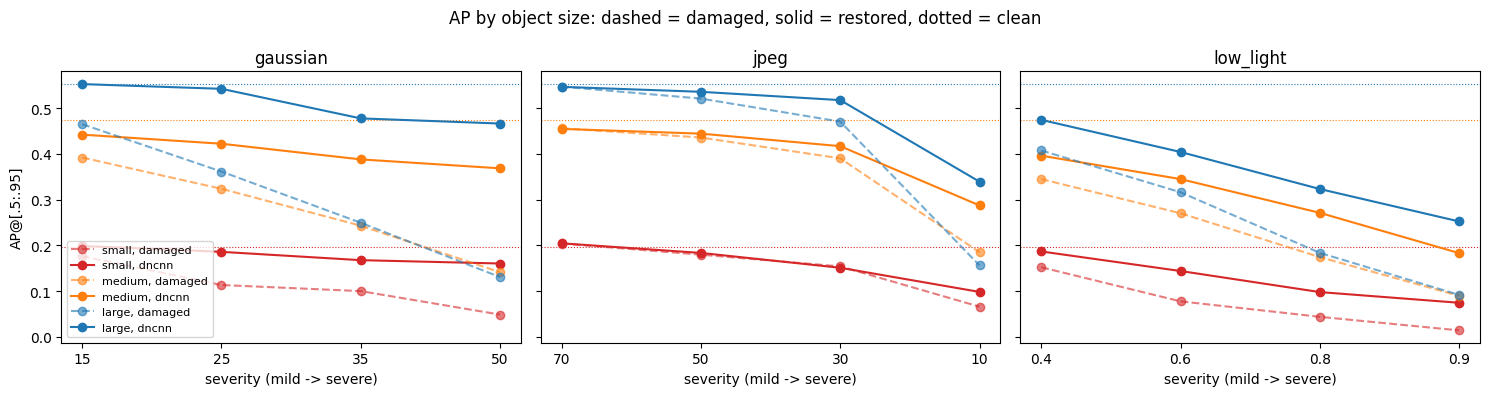

In [11]:
SIZES = ["ap_small", "ap_medium", "ap_large"]
clean_row = df[df.degradation == "clean"].iloc[0]
size_tab = df[df.degradation != "clean"].set_index(["degradation", "severity", "restorer"])[SIZES + ["map"]]
size_tab.round(3).to_csv(f"{OUT_DIR}/ap_by_size.csv")
print("clean AP by size:", {k: round(float(clean_row[k]), 3) for k in SIZES}, "| objects:", size_counts)

# Share of each size's clean AP that survives the damage, and share of the loss each restorer wins back
lines = []
for name, levels in CONDITIONS.items():
    for s in levels:
        base = size_tab.loc[(name, s, "none")]
        line = {"condition": f"{name} {s}"}
        for k in SIZES:
            line[f"kept_{k[3:]}"] = base[k] / clean_row[k]
        best = "dncnn" if name != "jpeg" else "classical"
        rest = size_tab.loc[(name, s, best)]
        for k in SIZES:
            lost = clean_row[k] - base[k]
            line[f"recovered_{k[3:]}"] = (rest[k] - base[k]) / lost if lost > 1e-6 else np.nan
        line["restorer"] = best
        lines.append(line)
sizes_summary = pd.DataFrame(lines)
print("\nkept = damaged AP / clean AP; recovered = share of the lost AP won back by the best restorer for that damage")
print((sizes_summary.set_index(["condition", "restorer"]) * 100).round(0).to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, name in zip(axes, CONDITIONS):
    for k, c in zip(SIZES, ["#d62728", "#ff7f0e", "#1f77b4"]):
        none = [size_tab.loc[(name, s, "none")][k] for s in CONDITIONS[name]]
        best = "dncnn" if name != "jpeg" else "classical"
        fix = [size_tab.loc[(name, s, best)][k] for s in CONDITIONS[name]]
        x = [str(s) for s in CONDITIONS[name]]
        ax.plot(x, none, "o--", color=c, alpha=0.6, label=f"{k[3:]}, damaged")
        ax.plot(x, fix, "o-", color=c, label=f"{k[3:]}, {best}")
        ax.axhline(clean_row[k], color=c, lw=0.8, ls=":")
    ax.set_title(name); ax.set_xlabel("severity (mild -> severe)")
axes[0].set_ylabel("AP@[.5:.95]"); axes[0].legend(fontsize=8)
plt.suptitle("AP by object size: dashed = damaged, solid = restored, dotted = clean")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/ap_by_size.png", dpi=150); plt.show()

## 9 · Win 3: BM3D against DnCNN for detection

In [12]:
g = df[df.degradation == "gaussian"].pivot_table(index="severity", columns="restorer", values=["map", "psnr"])
print(g.round(3).to_string())
if "bm3d" in df.restorer.values:
    for s in BM3D_SIGMAS:
        for a, b in [("dncnn", "bm3d"), ("bm3d", "classical")]:
            r = lookup("gaussian", s, a, b)
            if r:
                print(f"sigma {s}: {a} - {b} = {r['diff']:+.3f} AP (95% CI {r['ci_low']:+.3f} to {r['ci_high']:+.3f})"
                      f"{'  clear' if r['clear'] else ''}")

            map                            psnr                          
restorer   bm3d classical  dncnn   none    bm3d classical   dncnn    none
severity                                                                 
15.0      0.371     0.359  0.375  0.319  32.848    30.956  32.907  24.944
25.0      0.343     0.305  0.354  0.241  29.979    27.574  30.729  20.695
35.0      0.327     0.264  0.326  0.181  27.939    25.727  29.275  17.968
50.0      0.297     0.169  0.304  0.088  25.541    22.565  27.715  15.190
sigma 15: dncnn - bm3d = +0.004 AP (95% CI -0.004 to +0.012)
sigma 15: bm3d - classical = +0.006 AP (95% CI -0.006 to +0.019)
sigma 25: dncnn - bm3d = +0.008 AP (95% CI -0.003 to +0.019)
sigma 25: bm3d - classical = +0.021 AP (95% CI +0.004 to +0.039)  clear
sigma 35: dncnn - bm3d = +0.010 AP (95% CI -0.000 to +0.021)
sigma 35: bm3d - classical = +0.047 AP (95% CI +0.027 to +0.068)  clear
sigma 50: dncnn - bm3d = +0.013 AP (95% CI +0.000 to +0.027)  clear
sigma 50: bm3d - class

## 10 · Win 4: low light, brighten and denoise in both orders

mAP:
severity         0.4    0.6    0.8    0.9
restorer                                 
none           0.274  0.207  0.121  0.056
classical      0.286  0.226  0.134  0.088
dncnn          0.325  0.283  0.213  0.159
clahe_L        0.250  0.174  0.095  0.044
gamma          0.267  0.165  0.059  0.024
gamma>dncnn    0.349  0.305  0.242  0.172
dncnn>gamma    0.341  0.283  0.196  0.150
dncnn>clahe_L  0.328  0.275  0.212  0.158
clahe_L>dncnn  0.279  0.215  0.148  0.089

PSNR (dB):
severity         0.4    0.6    0.8    0.9
restorer                                 
none           11.82   9.55   8.13   7.61
classical      11.86   9.57   8.16   7.65
dncnn          11.88   9.55   8.07   7.51
clahe_L        15.12  12.45  10.37   9.50
gamma          18.17  15.45  12.81  11.38
gamma>dncnn    20.91  19.10  16.17  14.41
dncnn>gamma    20.37  18.54  16.71  15.71
dncnn>clahe_L  15.19  11.97   9.70   8.78
clahe_L>dncnn  15.43  12.61  10.48   9.59

best for detection at each level: {0.4: 'gamma>dncnn', 0.6

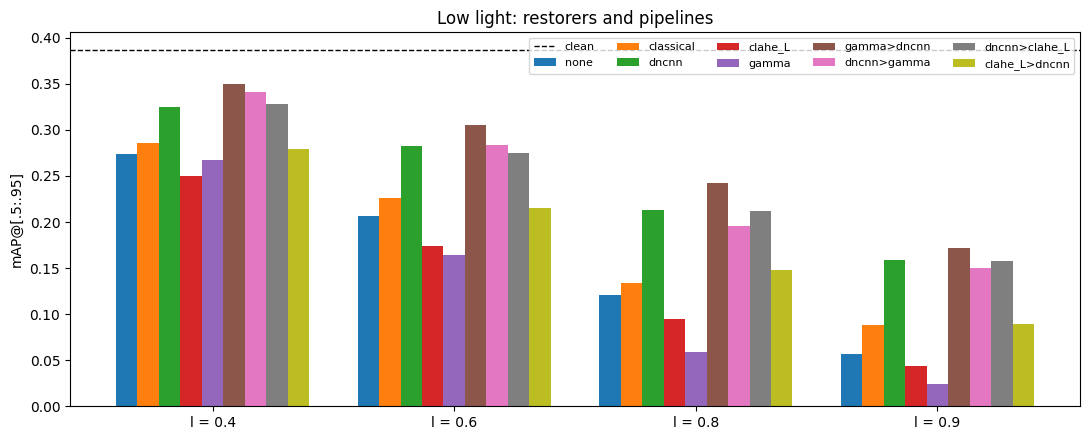

l = 0.4: best PSNR = gamma>dncnn    best mAP = gamma>dncnn
l = 0.6: best PSNR = gamma>dncnn    best mAP = gamma>dncnn
l = 0.8: best PSNR = dncnn>gamma    best mAP = gamma>dncnn
l = 0.9: best PSNR = dncnn>gamma    best mAP = gamma>dncnn


In [13]:
LL = APPLIES["low_light"]
ll = df[df.degradation == "low_light"].pivot_table(index="restorer", columns="severity", values="map").loc[LL]
llp = df[df.degradation == "low_light"].pivot_table(index="restorer", columns="severity", values="psnr").loc[LL]
print("mAP:"); print(ll.round(3).to_string())
print("\nPSNR (dB):"); print(llp.round(2).to_string())
best_per_level = ll.idxmax()
print("\nbest for detection at each level:", best_per_level.to_dict())
for s in CONDITIONS["low_light"]:
    b = best_per_level[s]
    if b != "dncnn":
        r = lookup("low_light", s, b, "dncnn")
        print(f"l = {s}: {b} vs dncnn alone: {r['diff']:+.3f} AP (95% CI {r['ci_low']:+.3f} to {r['ci_high']:+.3f})"
              f"{'  clear' if r['clear'] else ''}")

fig, ax = plt.subplots(figsize=(11, 4.5))
w = 0.8 / len(LL)
for j, r in enumerate(LL):
    ax.bar(np.arange(4) + j * w, ll.loc[r].values, w, label=r)
ax.axhline(clean_map, ls="--", color="k", lw=1, label="clean")
ax.set_xticks(np.arange(4) + 0.4 - w / 2); ax.set_xticklabels([f"l = {s}" for s in CONDITIONS["low_light"]])
ax.set_ylabel("mAP@[.5:.95]"); ax.legend(ncol=5, fontsize=8); ax.set_title("Low light: restorers and pipelines")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/low_light_pipelines.png", dpi=150); plt.show()

# Does PSNR still pick the wrong method once the pipelines are included?
for s in CONDITIONS["low_light"]:
    print(f"l = {s}: best PSNR = {llp[s].idxmax():14s} best mAP = {ll[s].idxmax()}")

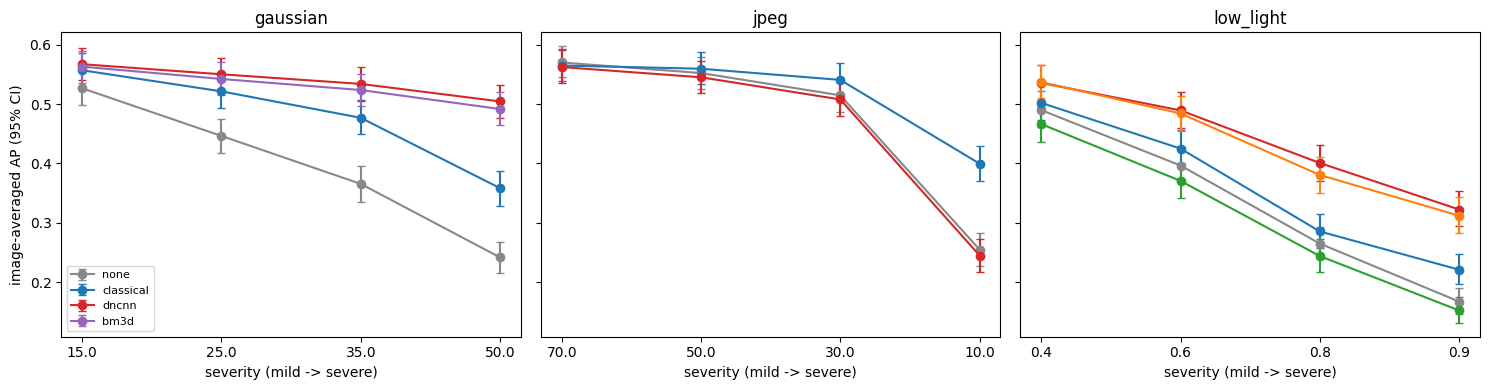

outputs: ['ap_by_size.csv', 'ap_by_size.png', 'ap_with_ci.png', 'bm3d_bsd_psnr.csv', 'bootstrap_pairs.csv', 'bootstrap_runs.csv', 'low_light_pipelines.png', 'per_image_ap.csv', 'subset_ids.json', 'sweep.csv']


In [14]:
# Error-bar version of the report's main figure (mAP vs severity), using the bootstrap intervals
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
COL = {"none": "#888888", "classical": "#1f77b4", "dncnn": "#d62728", "clahe_L": "#2ca02c", "bm3d": "#9467bd",
       "dncnn>gamma": "#ff7f0e"}
for ax, name in zip(axes, CONDITIONS):
    for r, c in COL.items():
        sub = runs[(runs.degradation == name) & (runs.restorer == r)].set_index("severity")
        if not len(sub):
            continue
        sub = sub.loc[[s for s in CONDITIONS[name] if s in sub.index]]
        x = [str(s) for s in sub.index]
        ax.errorbar(x, sub.img_avg_ap, yerr=[sub.img_avg_ap - sub.ci_low, sub.ci_high - sub.img_avg_ap],
                    fmt="o-", color=c, capsize=3, label=r)
    ax.set_title(name); ax.set_xlabel("severity (mild -> severe)")
axes[0].set_ylabel("image-averaged AP (95% CI)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/ap_with_ci.png", dpi=150); plt.show()
print("outputs:", sorted(os.listdir(OUT_DIR)))

## 11 · What to send back

Download the `outputs/05b` folder (or send the committed notebook). The report gets:
1. confidence intervals on the section 11 table, and which differences are clear;
2. an object-size breakdown;
3. BM3D in the section 10 PSNR table and the section 11 detection table;
4. the low-light pipeline results, which test the explanation in section 12 directly.